# Project Summary
#### objective
- To perform wound segmentation and extracting properties
#### Methods and tools
- Dataset : Kaggle-wound images
- U-Net
- Cross validation
- OpenCV
- Tensorflow
#### Result
- Accuracy: 0.9827 (validation)

#### Extra
- Web App using streamlit
- LLM integration -DeepSeek open API (free version)

#### Challenges
- Resources: GPU (even this environment is limitted)

# Import libraries

In [2]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import MeanIoU
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

2025-06-06 07:14:18.284113: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1749194058.475374      31 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1749194058.528204      31 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


# Data Preprocessing

## Load data

In [11]:
import os

base_path = "/kaggle/input/wound-segmentation-images/data_wound_seg"

# List top-level contents
print("Contents of base path:")
for item in os.listdir(base_path):
    print("  -", item)


Contents of base path:
  - train_images
  - test_masks
  - train_masks
  - correspondence_table.xlsx
  - test_images


In [12]:
import os
from glob import glob

data_folder = "/kaggle/input/wound-segmentation-images/data_wound_seg"

train_image_path = sorted(glob(os.path.join(data_folder, "train_images", "*.png")))
train_mask_path = sorted(glob(os.path.join(data_folder, "train_masks", "*.png")))

test_image_path = sorted(glob(os.path.join(data_folder, "test_images", "*.png")))
test_mask_path = sorted(glob(os.path.join(data_folder, "test_masks", "*.png")))

print(f"Total train images: {len(train_image_path)}\nTotal train masks: {len(train_mask_path)}")
print(f"Total test images: {len(test_image_path)}\nTotal test masks: {len(test_mask_path)}")


Total train images: 2208
Total train masks: 2208
Total test images: 552
Total test masks: 552


## Display sample

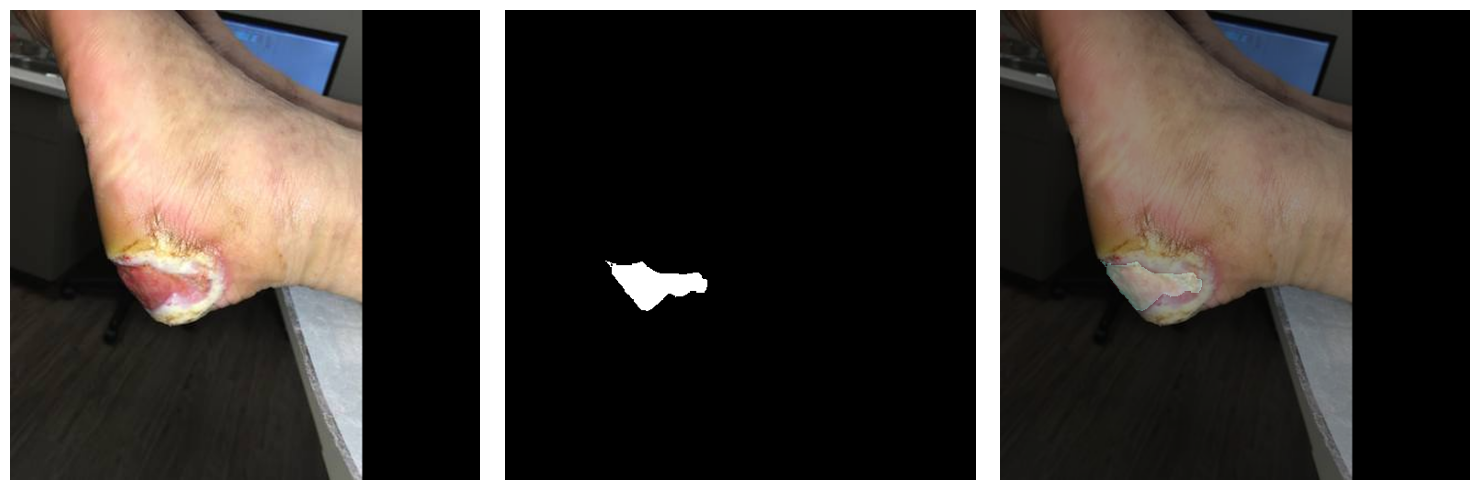

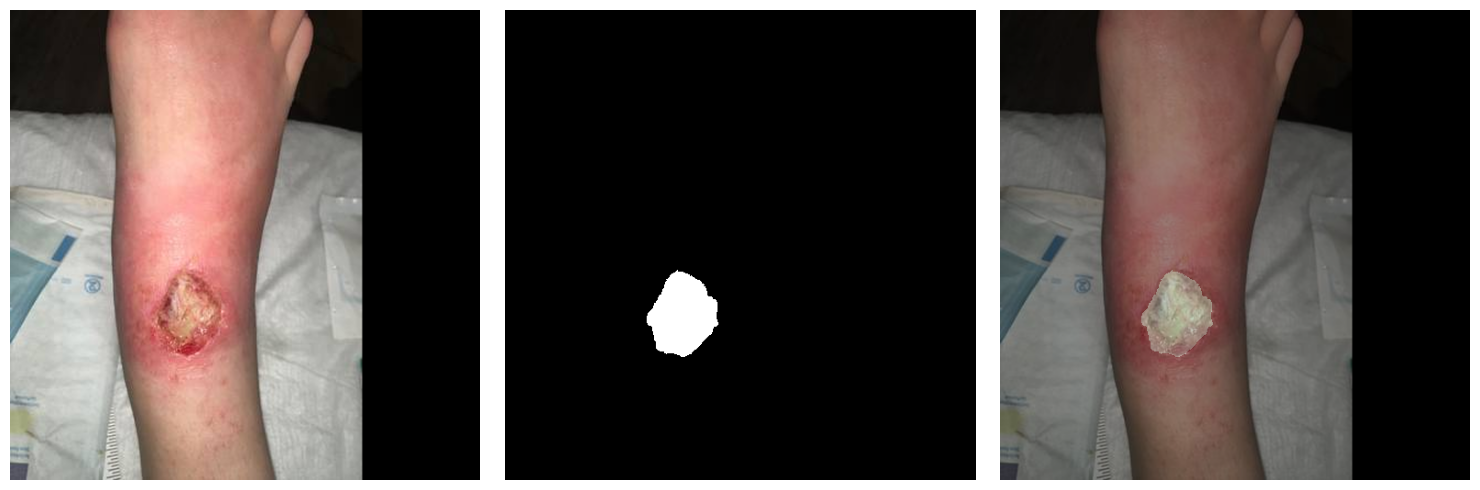

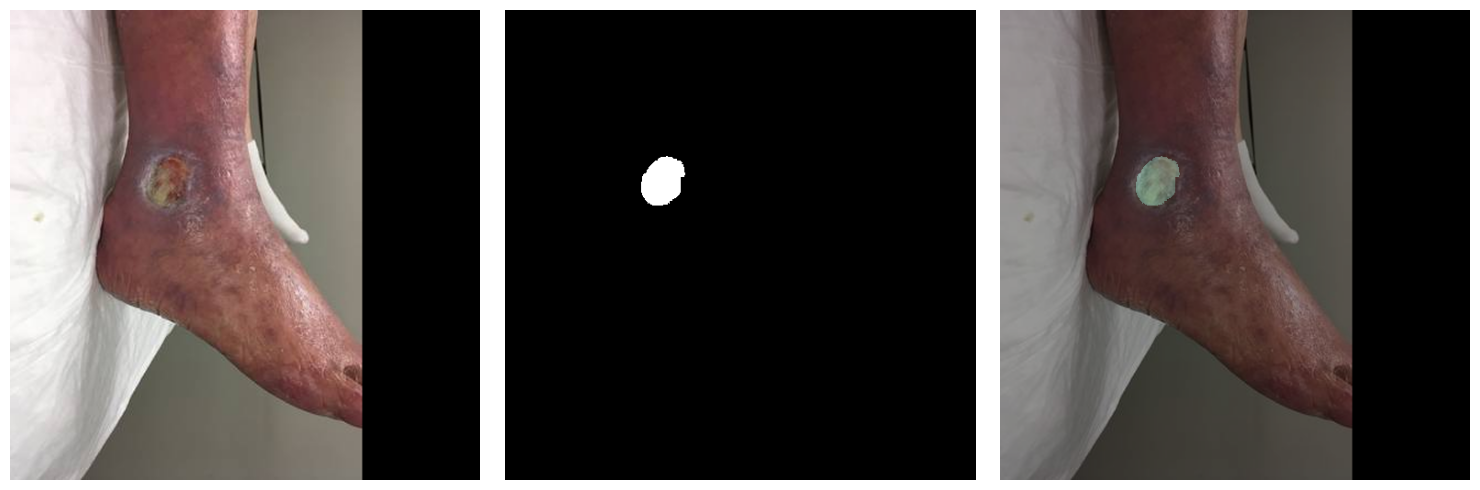

In [13]:
def get_colored_mask(image, mask_image,color = [103,193,173]):
    mask_image_gray = cv2.cvtColor(mask_image, cv2.COLOR_BGR2GRAY)
    mask = cv2.bitwise_and(mask_image, mask_image, mask=mask_image_gray)
    mask_coord = np.where(mask!=[0,0,0])
    mask[mask_coord[0],mask_coord[1],:]= color
    ret = cv2.addWeighted(image, 0.6, mask, 0.4, 0)
    return ret

trn_imgs = train_image_path[:3]
trn_msks = train_mask_path[:3]

for img_path,msk_path in zip(trn_imgs,trn_msks):
    img = cv2.imread(img_path)
    msk = cv2.imread(msk_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(15,5))

    plt.subplot(131)
    plt.imshow(img)
    plt.yticks([])
    plt.xticks([])
    plt.box(False)

    plt.subplot(132)
    msk_gray = cv2.cvtColor(msk, cv2.COLOR_BGR2GRAY)
    plt.imshow(msk_gray, cmap='binary_r')
    plt.yticks([])
    plt.xticks([])
    plt.box(False)

    plt.subplot(133)
    plt.imshow(get_colored_mask(img, msk))
    plt.yticks([])
    plt.xticks([])
    plt.box(False)

    plt.tight_layout()
    plt.show()

## Preprocess images and masks

In [14]:
from tensorflow.keras.utils import Sequence

IMG_HEIGHT = 256
IMG_WIDTH = 256

class SegmentationDataGenerator(Sequence):
    def __init__(self, image_paths, mask_paths, batch_size=8, shuffle=True):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.image_paths))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.image_paths) / self.batch_size))

    def __getitem__(self, index):
        # Get batch indexes
        batch_indices = self.indices[index * self.batch_size:(index + 1) * self.batch_size]

        # Initialize batches
        batch_images = []
        batch_masks = []

        for i in batch_indices:
            # Load and preprocess image
            image = cv2.imread(self.image_paths[i])
            image = cv2.resize(image, (IMG_WIDTH, IMG_HEIGHT))
            image = image / 255.0

            # Load and preprocess mask
            mask = cv2.imread(self.mask_paths[i], cv2.IMREAD_GRAYSCALE)
            mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT))
            mask = np.expand_dims(mask, axis=-1)
            mask = mask / 255.0
            mask = np.round(mask)

            batch_images.append(image)
            batch_masks.append(mask)

        return np.array(batch_images), np.array(batch_masks)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


## Data split(train/validate)

In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    train_image_path, train_mask_path,
    test_size=0.2,
    random_state=42,
    shuffle=True
)


## Generate training and validation data

In [16]:
train_data = SegmentationDataGenerator(X_train, y_train, batch_size=32)
val_data = SegmentationDataGenerator(X_val, y_val, batch_size=32)

# U-Net model

## Model architecture

In [17]:
def unet_model(input_size=(256, 256, 3)):
    inputs = Input(input_size)

    # Encoder
    c1 = Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
    c1 = Conv2D(64, (3, 3), activation='relu', padding='same')(c1)
    p1 = MaxPooling2D((2, 2))(c1)

    c2 = Conv2D(128, (3, 3), activation='relu', padding='same')(p1)
    c2 = Conv2D(128, (3, 3), activation='relu', padding='same')(c2)
    p2 = MaxPooling2D((2, 2))(c2)

    c3 = Conv2D(256, (3, 3), activation='relu', padding='same')(p2)
    c3 = Conv2D(256, (3, 3), activation='relu', padding='same')(c3)
    p3 = MaxPooling2D((2, 2))(c3)

    c4 = Conv2D(512, (3, 3), activation='relu', padding='same')(p3)
    c4 = Conv2D(512, (3, 3), activation='relu', padding='same')(c4)
    p4 = MaxPooling2D((2, 2))(c4)

    # Bottleneck
    c5 = Conv2D(1024, (3, 3), activation='relu', padding='same')(p4)
    c5 = Conv2D(1024, (3, 3), activation='relu', padding='same')(c5)

    # Decoder
    u6 = Conv2DTranspose(512, (2, 2), strides=(2, 2), padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(512, (3, 3), activation='relu', padding='same')(u6)
    c6 = Conv2D(512, (3, 3), activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(256, (3, 3), activation='relu', padding='same')(u7)
    c7 = Conv2D(256, (3, 3), activation='relu', padding='same')(c7)

    u8 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(128, (3, 3), activation='relu', padding='same')(u8)
    c8 = Conv2D(128, (3, 3), activation='relu', padding='same')(c8)

    u9 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(c8)
    u9 = concatenate([u9, c1])
    c9 = Conv2D(64, (3, 3), activation='relu', padding='same')(u9)
    c9 = Conv2D(64, (3, 3), activation='relu', padding='same')(c9)

    outputs = Conv2D(1, (1, 1), activation='sigmoid')(c9)

    model = Model(inputs=[inputs], outputs=[outputs])
    return model

# Build the model
model = unet_model()
model.summary()


I0000 00:00:1749194072.614094      31 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 256, 256, 3)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 256, 256, 64)   │          1,792 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 256, 256, 64)   │         36,928 │ conv2d[0][0]           │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 128, 128, 64)   │              0 │ conv2d_1[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 128, 128, 128)  │         73,856 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 128, 128, 128)  │        147,584 │ conv2d_2[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_1           │ (None, 64, 64, 128)    │              0 │ conv2d_3[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 64, 64, 256)    │        295,168 │ max_pooling2d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_5 (Conv2D)         │ (None, 64, 64, 256)    │        590,080 │ conv2d_4[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_2           │ (None, 32, 32, 256)    │              0 │ conv2d_5[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_6 (Conv2D)         │ (None, 32, 32, 512)    │      1,180,160 │ max_pooling2d_2[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_7 (Conv2D)         │ (None, 32, 32, 512)    │      2,359,808 │ conv2d_6[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_3           │ (None, 16, 16, 512)    │              0 │ conv2d_7[0][0]         │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_8 (Conv2D)         │ (None, 16, 16, 1024)   │      4,719,616 │ max_pooling2d_3[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_9 (Conv2D)         │ (None, 16, 16, 1024)   │      9,438,208 │ conv2d_8[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_transpose          │ (None, 32, 32, 512)    │      2,097,664 │ conv2d_9[0][0]         │
│ (Conv2DTranspose)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate (Concatenate) │ (None, 32, 32, 1024)   │              0 │ conv2d_transpose[0][0… │
│                      

 Total params: 31,031,745 (118.38 MB)

 Trainable params: 31,031,745 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

## Model training and validation

In [18]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
# Callbacks
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    'best_wound_unet_model.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Fit the model
history = model.fit(
    train_data,   
    validation_data=val_data,
    epochs=100,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1749194095.282626     100 service.cc:148] XLA service 0x78d3b0009d40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1749194095.283753     100 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1749194096.286175     100 cuda_dnn.cc:529] Loaded cuDNN version 90300
2025-06-06 07:15:02.581424: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng12{k11=2} for conv (f32[32,128,128,128]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,128,128,128]{3,2,1,0}, f32[128,128,3,3]{3,2,1,0}, f32[128]{0}

31/56 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.8454 - loss: 0.8479

E0000 00:00:1749194201.502006      99 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1749194201.735646      99 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1749194202.342802      99 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1749194202.604107      99 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8856 - loss: 0.6725

E0000 00:00:1749194286.439732     101 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1749194286.684697     101 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1749194286.923854     101 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1749194288.158485     101 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1749194288.422396     101 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from inf to 0.15670, saving model to best_wound_unet_model.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 225s 3s/step - accuracy: 0.8866 - loss: 0.6676 - val_accuracy: 0.9535 - val_loss: 0.1567 - learning_rate: 0.0010
Epoch 2/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 677ms/step - accuracy: 0.9560 - loss: 0.1528
Epoch 2: val_loss improved from 0.15670 to 0.14431, saving model to best_wound_unet_model.keras
56/56 ━━━━━━━━━━━━━━━━━━━━ 50s 834ms/step - accuracy: 0.9560 - loss: 0.1528 - val_accuracy: 0.9535 - val_loss: 0.1443 - learning_rate: 0.0010
Epoch 3/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 672ms/step - accuracy: 0.9569 - loss: 0.1422
Epoch 3: val_loss did not improve from 0.14431
56/56 ━━━━━━━━━━━━━━━━━━━━ 48s 796ms/step - accuracy: 0.9569 - loss: 0.1423 - val_accuracy: 0.9541 - val_loss: 0.1492 - learning_rate: 0.0010
Epoch 4/100
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 677ms/step - accuracy: 0.9567 - loss: 0.1453
Epoch 4: val_loss improved from 0.14431 to 0.13947, saving model to best_wound_

In [19]:
# checkpoint_path = "best_unet_model.keras"

# callbacks = [
#     EarlyStopping(patience=5, restore_best_weights=True),
#     ModelCheckpoint(checkpoint_path, save_best_only=True)
# ]

# history = model.fit(
#     train_data,
#     validation_data=val_data,
#     epochs=30,
#     callbacks=callbacks
# )


## Training performance

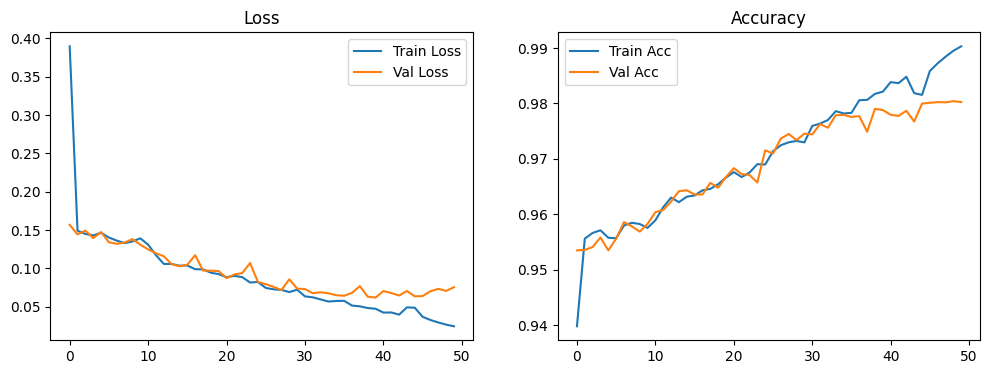

In [20]:
# Plot accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss")

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title("Accuracy")

plt.show()


# Segmentation and Properties extraction

## Prediction

In [21]:
test_data = SegmentationDataGenerator(test_image_path, test_mask_path, batch_size=32)

tst_images,tst_masks = test_data[0]
preds = model.predict(tst_images,batch_size=32)

preds_thresh = (preds > 0.5).astype(np.uint8)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


## Wound properties extraction - predicted

In [22]:
def extract_wound_properties(image, mask):
    props = {
        "bounding_boxes": [],
        "area": 0,
        "avg_color": (0, 0, 0)
    }

    # Convert mask to binary
    mask_bin = (mask.squeeze() > 0.5).astype(np.uint8)

    # Find all contours
    contours, _ = cv2.findContours(mask_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # Total wound area and pixel collection
    all_wound_pixels = []

    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        props["bounding_boxes"].append((x, y, w, h))
        cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)
        
        # Create a mask for this contour only
        cnt_mask = np.zeros_like(mask_bin)
        cv2.drawContours(cnt_mask, [cnt], -1, color=1, thickness=-1)
        
        # Extract wound pixels for this region
        wound_pixels = image[cnt_mask == 1]
        all_wound_pixels.append(wound_pixels)

        # Add to total area
        props["area"] += int(np.sum(cnt_mask))

    if all_wound_pixels:
        # Concatenate all wound pixels to compute global average color
        all_pixels = np.concatenate(all_wound_pixels, axis=0)
        avg_color = all_pixels.mean(axis=0)
        props["avg_color"] = tuple(np.round(avg_color).astype(int))

    return props, image


## Bounding box - predicted

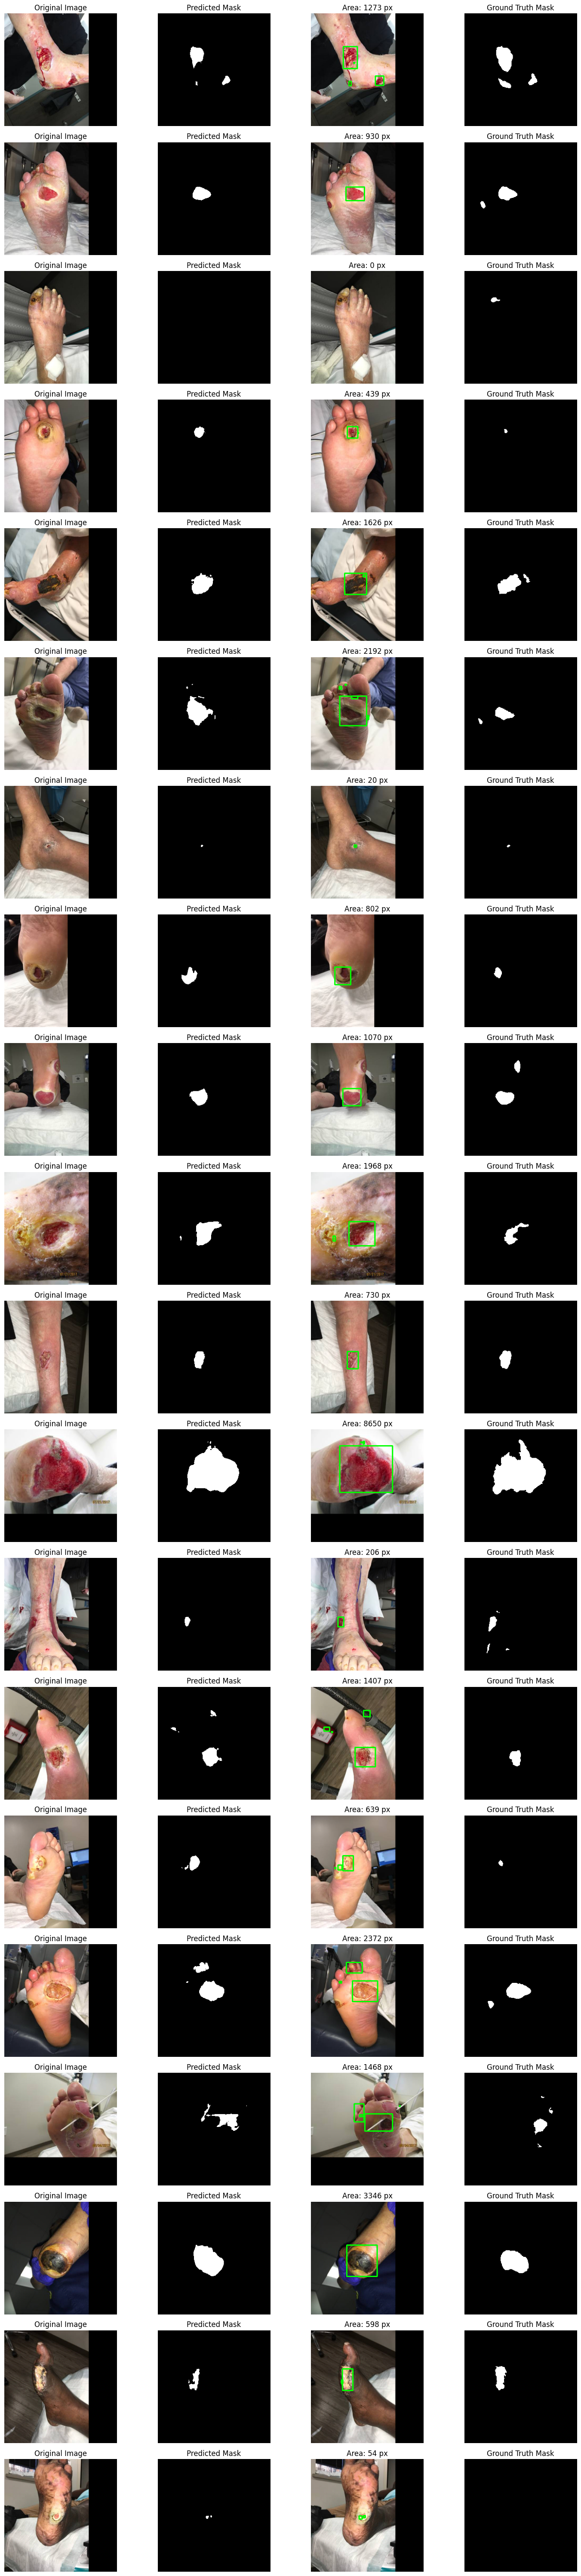

In [41]:
num_samples = 20  # Number of images to display
plt.figure(figsize=(15, num_samples * 3))  # Adjust height based on number of samples

for i in range(num_samples):
    img = (tst_images[i] * 255).astype(np.uint8)
    # msk = cv2.imread(tst_masks[i])
    # msk = cv2.imread(tst_masks[i], cv2.IMREAD_GRAYSCALE)
    msk = tst_masks[i]
    mask_pred = preds_thresh[i]

    # Convert to RGB for correct color display
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Extract wound info and image with bounding box
    props, image_with_box = extract_wound_properties(img_rgb.copy(), mask_pred)
    
    # Plot Original Image
    plt.subplot(num_samples, 4, i * 4 + 1)
    plt.imshow(img_rgb)
    plt.title("Original Image")
    plt.axis('off')

    # Plot Predicted Mask
    plt.subplot(num_samples, 4, i * 4 + 2)
    plt.imshow(mask_pred.squeeze(), cmap='gray')
    plt.title("Predicted Mask")
    plt.axis('off')

    # Plot Image with Bounding Box
    plt.subplot(num_samples, 4, i * 4 + 3)
    plt.imshow(image_with_box)
    plt.title(f"Area: {props['area']} px")
    plt.axis('off')

    # Plot Image with Bounding Box
    # plt.subplot(num_samples, 4, i * 4 + 4)
    # plt.imshow(get_colored_mask(img_rgb, msk))
    # plt.title("Ground truth")
    # plt.axis('off')

    plt.subplot(num_samples, 4, i * 4 + 4)
    if len(msk.shape) == 3 and msk.shape[2] == 3:
        msk = cv2.cvtColor(msk, cv2.COLOR_BGR2GRAY)
    plt.imshow(msk.squeeze(), cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis('off')

#  plt.imshow(get_colored_mask(img, msk))
plt.tight_layout()
plt.show()


# Model save

In [31]:
model.save("best_wound_unet_model_last.keras")